In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8')
sns.set_palette('husl')
DATA_DIR = '../data/raw'

In [2]:
df = pd.read_csv(f'{DATA_DIR}/diabetes.csv')
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
df.head()

Shape: (768, 9)
Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Outcome
0    500
1    268
Name: count, dtype: int64


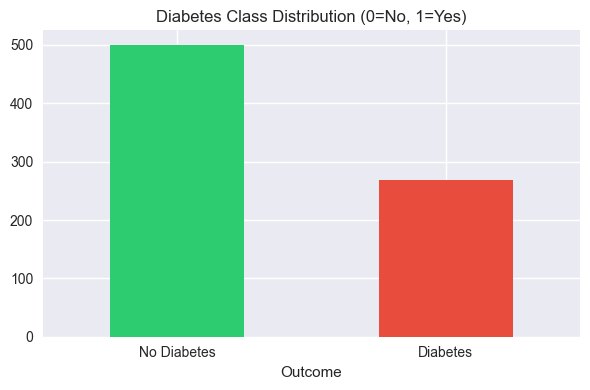

In [4]:
target_counts = df['Outcome'].value_counts()
print(target_counts)

plt.figure(figsize=(6, 4))
target_counts.plot(kind='bar', color=['#2ecc71', '#e74c3c'])
plt.title('Diabetes Class Distribution (0=No, 1=Yes)')
plt.xticks([0, 1], ['No Diabetes', 'Diabetes'], rotation=0)
plt.tight_layout()
plt.savefig('../reports/eda_diabetes_target.png', dpi=150)
plt.show()

In [5]:
# Which columns have 0s where 0 is invalid?
invalid_zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

for col in invalid_zero_cols:
    zeros = (df[col] == 0).sum()
    pct = (zeros / len(df)) * 100
    print(f"{col:20s}: {zeros:3d} zeros ({pct:.1f}%)")

Glucose             :   5 zeros (0.7%)
BloodPressure       :  35 zeros (4.6%)
SkinThickness       : 227 zeros (29.6%)
Insulin             : 374 zeros (48.7%)
BMI                 :  11 zeros (1.4%)


In [6]:
df_clean = df.copy()
df_clean[invalid_zero_cols] = df_clean[invalid_zero_cols].replace(0, np.nan)

print("Missing values after zero→NaN replacement:")
print(df_clean.isnull().sum())

Missing values after zero→NaN replacement:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


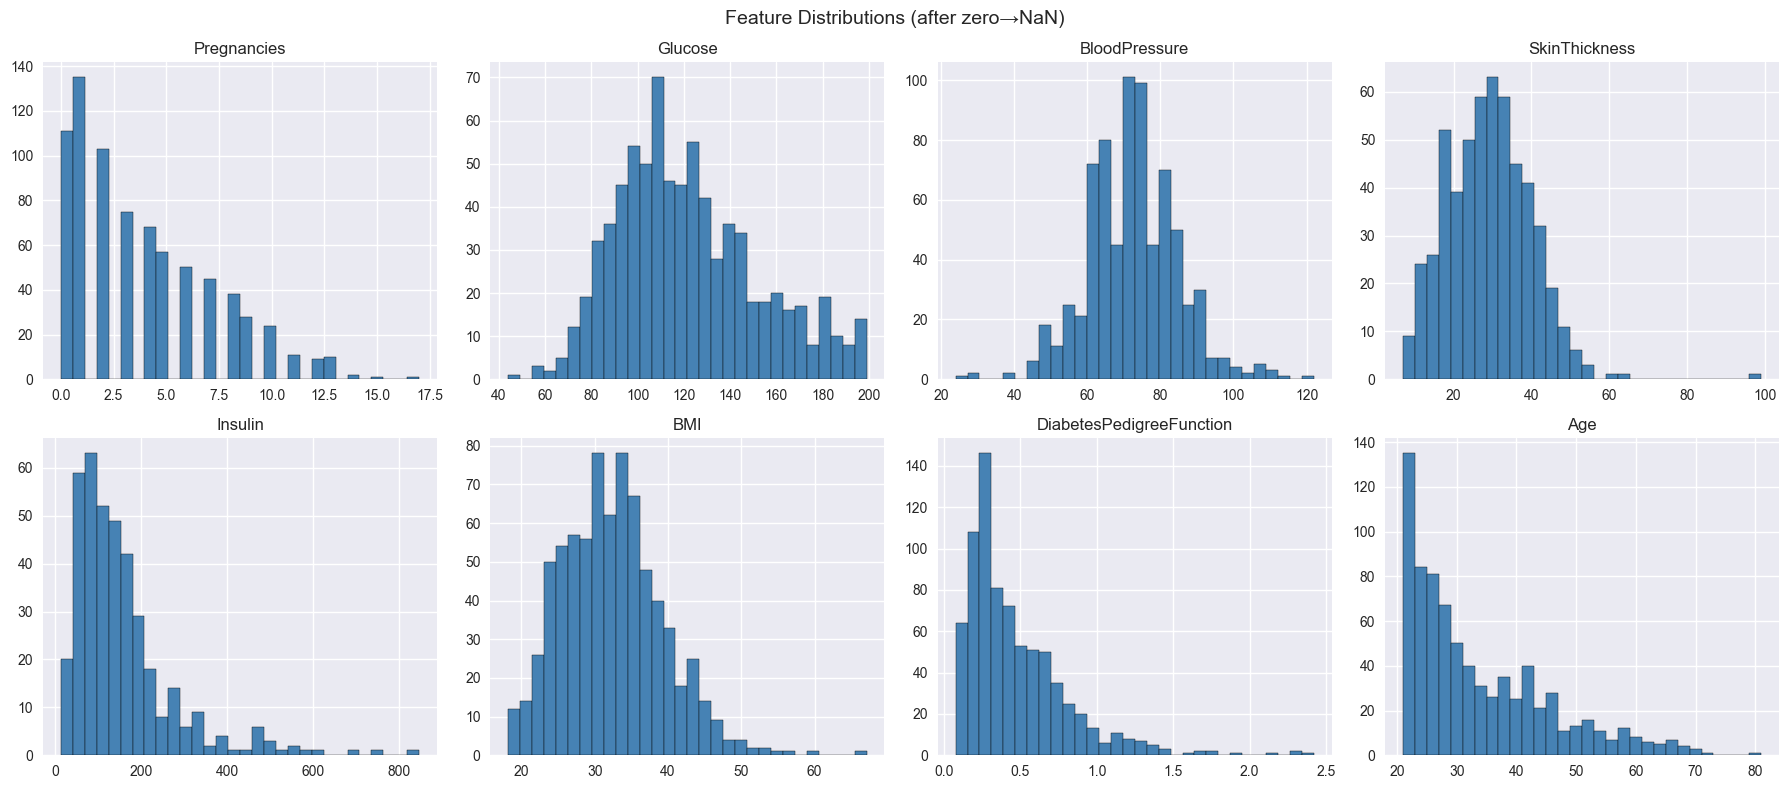

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
cols = df_clean.columns[:-1]  # exclude Outcome

for ax, col in zip(axes.flatten(), cols):
    df_clean[col].hist(ax=ax, bins=30, color='steelblue', edgecolor='black')
    ax.set_title(col)
    ax.set_xlabel('')

plt.suptitle('Feature Distributions (after zero→NaN)', fontsize=14)
plt.tight_layout()
plt.savefig('../reports/eda_diabetes_distributions.png', dpi=150)
plt.show()

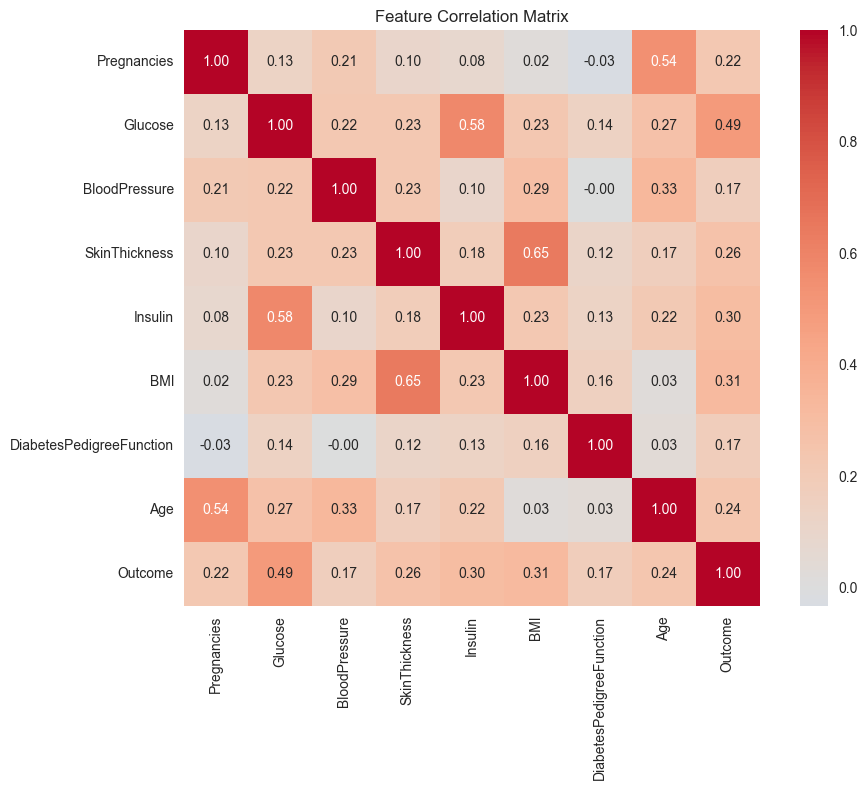


Correlations with Outcome:
Outcome                     1.000000
Glucose                     0.494650
BMI                         0.313680
Insulin                     0.303454
SkinThickness               0.259491
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
BloodPressure               0.170589
Name: Outcome, dtype: float64


In [8]:
plt.figure(figsize=(10, 8))
corr = df_clean.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.savefig('../reports/eda_diabetes_correlation.png', dpi=150)
plt.show()

# Top correlations with target
print("\nCorrelations with Outcome:")
print(corr['Outcome'].sort_values(ascending=False))

In [9]:
import os
os.makedirs('../data/processed', exist_ok=True)
df_clean.to_csv('../data/processed/diabetes_clean.csv', index=False)
print("✅ Saved: data/processed/diabetes_clean.csv")
print(f"   Shape: {df_clean.shape}")
print(f"   Missing values remaining: {df_clean.isnull().sum().sum()} (will impute in model notebook)")

✅ Saved: data/processed/diabetes_clean.csv
   Shape: (768, 9)
   Missing values remaining: 652 (will impute in model notebook)


## 📊 EDA Summary — PIMA Diabetes

### Key Findings
- **768 samples**, 8 features, binary target (Outcome)
- **Class imbalance:** 65% No / 35% Yes — mild, can be handled with class weights or SMOTE
- **Data quality issue:** Glucose, BloodPressure, SkinThickness, Insulin, BMI have 0 as "missing"
  - Insulin has 48.7% zeros — most affected

### Top Predictors (correlation with Outcome)
1. **Glucose** (0.49) — strongest
2. **BMI** (0.29)
3. **Age** (0.24)
4. **Pregnancies** (0.22)

### Preprocessing Decisions
- Replaced 0 → NaN in 5 columns
- Will impute with median (in model notebook, AFTER train/test split to avoid leakage)
- Plan: SMOTE on training set only
